we claim to do four things based on the dataset sourc code in dataset folder:
1. Downloads the public IDD processed dataset if it is missing.
2. Checks whether the DBM-derived gaze/control tables we need already exist and can generate them if the raw data is present.
3. Builds a subject-wise scenario manifest and visualizes label, duration, fold, and hazard coverage.
4. Loads one example multimodal chunk, visualizes gaze/control/video, and engineers aligned values plus missingness masks and time-delta features for later PyTorch models.

`sample` is only a sanity-check download.
For the real project use:
- `no-video` for gaze/control modeling first
- `only-scaled-rgb-video` for multimodal fusion with front video

In [13]:
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "dataset" / "README.md").exists():
            return candidate
    raise FileNotFoundError("Could not find the project root containing dataset/README.md.")

root = find_project_root(Path.cwd().resolve())
dbm_repo = root / "dataset"
data_dir = root / "data" / "IDD"

# Pick one:
version = "only-scaled-rgb-video"
# version = "no-video"
# version = "sample"

generate_missing_features = True
num_processes = 4

artifact_dir = root / "artifacts" / "bootstrap"
artifact_dir.mkdir(parents=True, exist_ok=True)

root

WindowsPath('C:/projects/DriverStateNet')

In [14]:
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

for name in list(sys.modules):
    if name == "data" or name.startswith("data."):
        sys.modules.pop(name, None)
    if name == "hail_datasets" or name.startswith("hail_datasets."):
        sys.modules.pop(name, None)

import src.data_bootstrap as data_bootstrap
import src

importlib.reload(data_bootstrap)
importlib.reload(src)

from src import (
    LABEL_ORDER,
    build_inspection_dataset,
    build_scenario_manifest,
    ensure_dbm_derived_features,
    ensure_processed_dataset,
    engineer_multimodal_sample,
    extract_video_frame,
    overlay_gaze_on_frame,
    select_example_sample,
)

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
np.set_printoptions(suppress=True)

## 1. Bootstrap the Dataset

`ensure_processed_dataset(...)` uses the public DBM release config and works on Windows as well.
In this notebook `data_dir` is just the folder that contains `idd_annotation.csv` and the `Resampled_*` folders.

Recommended choices:
- `sample`: quick sanity check only
- `no-video`: about 21 GB, enough for Iteration 0 and Iteration 1
- `only-scaled-rgb-video`: about 29 GB, recommended for your multimodal project

In [15]:
processed_root = ensure_processed_dataset(
    dbm_repo=dbm_repo,
    processed_root=data_dir,
    version=version,
    download_if_missing=True,
    prompt_for_license=True,
)
print(f"Using dataset at: {processed_root}")
print(f"Requested version: {version}")

derived_status = pd.DataFrame.from_dict(
    ensure_dbm_derived_features(
        dbm_repo=dbm_repo,
        processed_root=processed_root,
        run_missing=generate_missing_features,
        num_processes=num_processes,
    ),
    orient="index",
).sort_index()

display(derived_status)

Using dataset at: C:\projects\DriverStateNet\data\IDD
Requested version: only-scaled-rgb-video


,relative_dir,probe_file,present,generated
ego_tracks,Resampled_previous_10_derived,ego_tracks.csv,True,False
gaze_fixation_saccade,Resampled_previous_60_derived,gaze_fixation_saccade.csv,True,False
gaze_pitch_yaw,Resampled_previous_60_derived,gaze_pitch_yaw.csv,True,False
steering_reversals,Resampled_previous_10_derived,steering_reversals.csv,True,False


## 2. Build the Scenario Manifest

This manifest preserves the DBM subject-wise metadata and adds the four-class impairment label we will use for the transformer project:

- `baseline`
- `cognitive_distraction`
- `alcohol_intoxication`
- `combined`

In [16]:
manifest = build_scenario_manifest(
    dbm_repo=dbm_repo,
    processed_root=processed_root,
    scenario_name_filter=r"driving/[0-9].*",
)

manifest_path = artifact_dir / "scenario_manifest.csv"
manifest.to_csv(manifest_path, index=False)
print(f"Saved scenario manifest to {manifest_path}")

summary = pd.DataFrame(
    {
        "num_scenarios": [len(manifest)],
        "num_participants": [manifest["participant_name"].nunique()],
        "num_labels_present": [manifest["impairment_label"].nunique()],
        "num_hazard_scenarios": [manifest["scenario_code"].nunique()],
        "hours_of_data": [manifest["duration_s"].sum() / 3600.0],
    }
)

display(summary)
display(manifest.head())

Constructed dataset contains 52 participants, 371 scenarios, and 371 chunks.
Saved scenario manifest to C:\projects\DriverStateNet\artifacts\bootstrap\scenario_manifest.csv


,num_scenarios,num_participants,num_labels_present,num_hazard_scenarios,hours_of_data
0,371,52,4,8,21.114798


,participant_name,scenario_name,scenario_code,round,cognitive_task,is_cd,intoxicated,impairment_label,label_id,fixed_fold,duration_s,experiment_version,number_all_crashes,number_hazard_crashes,has_any_crash,has_hazard_crash,level_0,index,scenario_index,scenario_path,start_time,end_time,duration_frames,anomalies
0,7224,driving/2b-vehicle_door_open_hazard,2b,R1,no_task,False,False,baseline,0,3,225.087415,2,0,0,False,False,0,8,8,R1/driving/2b-vehicle_door_open_hazard/no_task,1724951349597690691,1724951574685105194,2251,[]
1,7224,driving/8a-pedestrian_pop_out,8a,R1,nback_task,True,False,cognitive_distraction,1,3,233.037594,2,0,0,False,False,1,9,9,R1/driving/8a-pedestrian_pop_out/nback_task,1724951730039958478,1724951963077552196,2331,[]
2,7224,driving/6e-vehicle_run_red_light,6e,R1,no_task,False,False,baseline,0,3,215.593040,2,1,-1,True,False,2,10,10,R1/driving/6e-vehicle_run_red_light/no_task,1724952075862407325,1724952291455447480,2156,[]
3,7224,driving/3c-pedestrian_pop_out,3c,R1,statement_task,True,False,cognitive_distraction,1,3,247.924779,2,2,0,True,False,3,11,11,R1/driving/3c-pedestrian_pop_out/statement_task,1724952395016534983,1724952642941313835,2480,[]
4,7224,driving/5-vehicle_run_stop,5,R2,no_task,False,False,baseline,0,3,265.452630,2,0,-1,False,False,4,17,17,R2/driving/5-vehicle_run_stop/no_task,1724953707364812708,1724953972817442291,2655,[]


C:\Users\FarzadA\AppData\Local\Temp\ipykernel_25972\3137252241.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, ax=axes[0, 0], palette="deep")
C:\Users\FarzadA\AppData\Local\Temp\ipykernel_25972\3137252241.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=duration_by_label.index, y=duration_by_label.values, ax=axes[0, 1], palette="crest")


Saved C:\projects\DriverStateNet\artifacts\bootstrap\manifest_overview.png


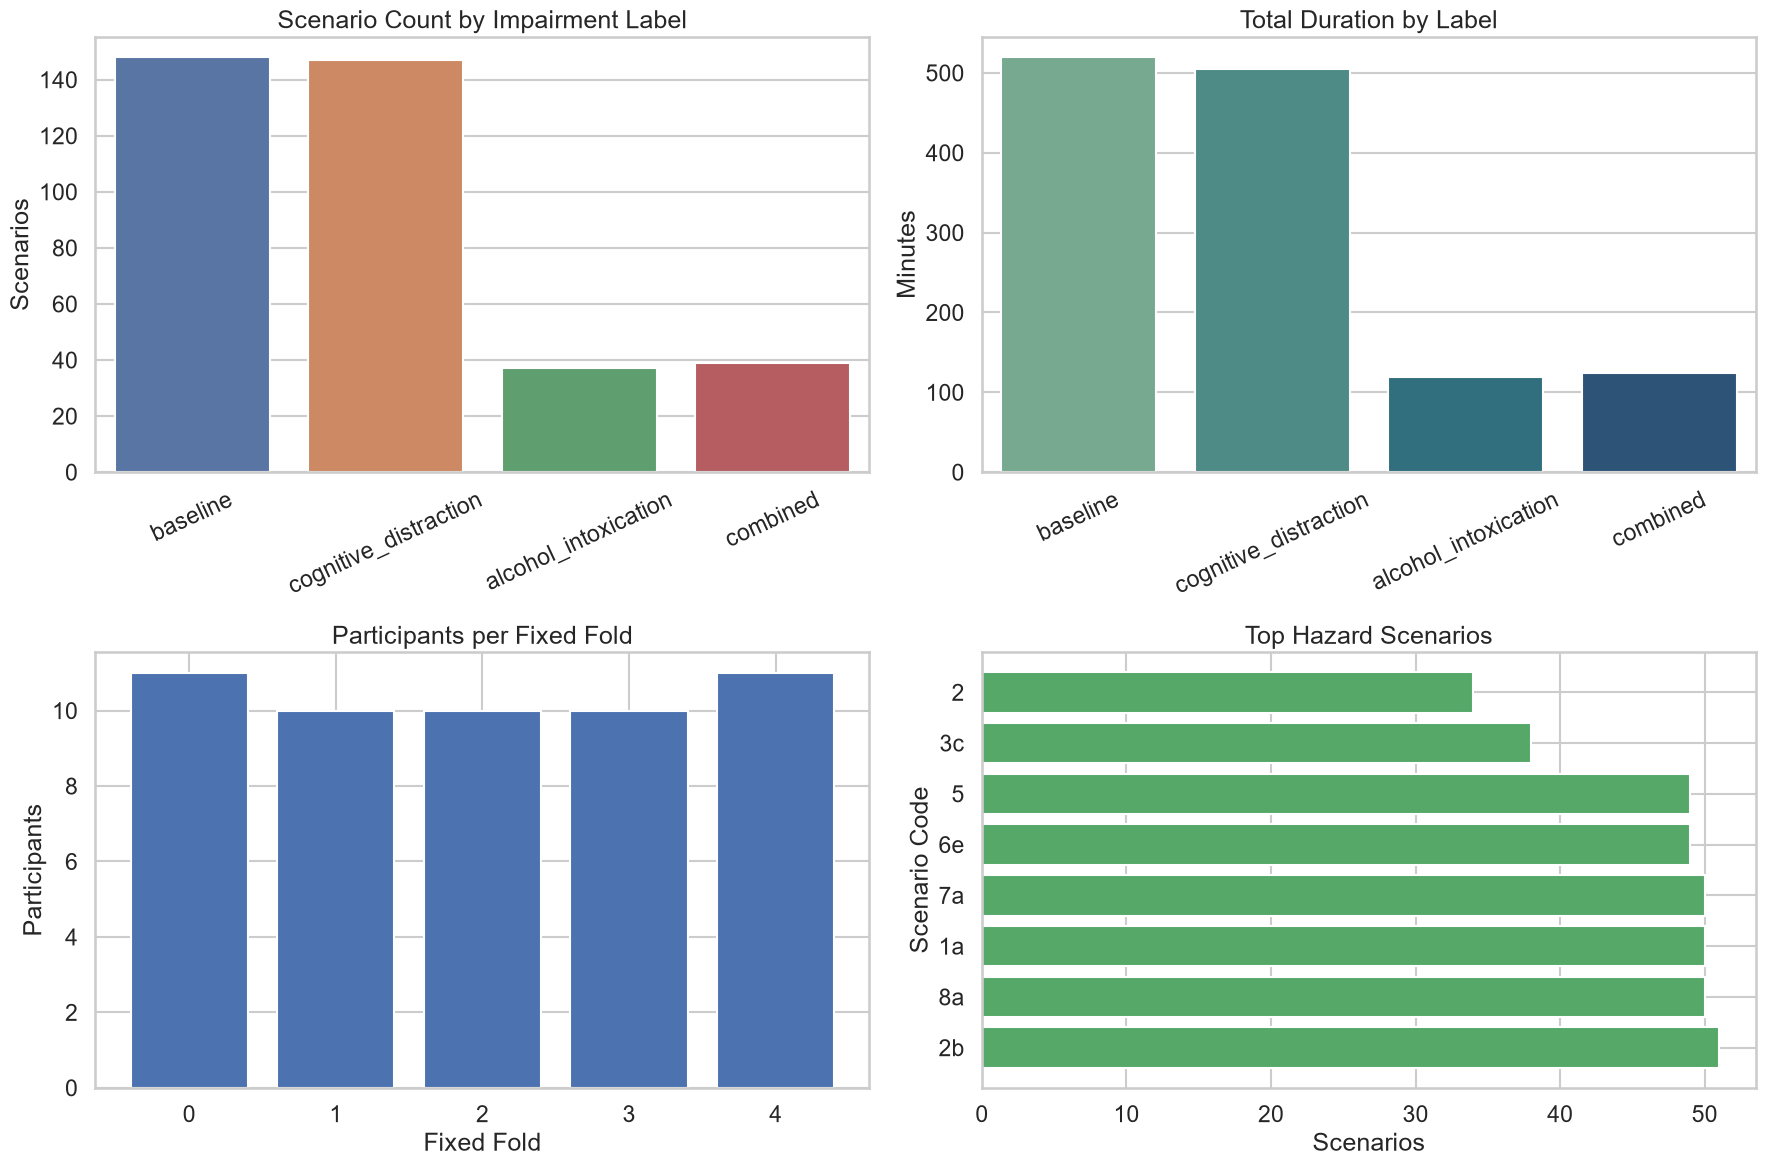

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

label_counts = manifest["impairment_label"].value_counts().reindex(LABEL_ORDER, fill_value=0)
sns.barplot(x=label_counts.index, y=label_counts.values, ax=axes[0, 0], palette="deep")
axes[0, 0].set_title("Scenario Count by Impairment Label")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Scenarios")
axes[0, 0].tick_params(axis="x", rotation=25)

duration_by_label = (
    manifest.groupby("impairment_label")["duration_s"].sum().reindex(LABEL_ORDER, fill_value=0) / 60.0
)
sns.barplot(x=duration_by_label.index, y=duration_by_label.values, ax=axes[0, 1], palette="crest")
axes[0, 1].set_title("Total Duration by Label")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Minutes")
axes[0, 1].tick_params(axis="x", rotation=25)

participant_counts = manifest.groupby("fixed_fold")["participant_name"].nunique().sort_index()
axes[1, 0].bar(
    participant_counts.index.astype(str).tolist(),
    participant_counts.astype(int).tolist(),
    color="#4C72B0",
)
axes[1, 0].set_title("Participants per Fixed Fold")
axes[1, 0].set_xlabel("Fixed Fold")
axes[1, 0].set_ylabel("Participants")

top_scenarios = manifest["scenario_code"].value_counts().head(12)
axes[1, 1].barh(
    top_scenarios.index.astype(str).tolist(),
    top_scenarios.astype(int).tolist(),
    color="#55A868",
)
axes[1, 1].set_title("Top Hazard Scenarios")
axes[1, 1].set_xlabel("Scenarios")
axes[1, 1].set_ylabel("Scenario Code")

fig.tight_layout()
fig_path = artifact_dir / "manifest_overview.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Saved {fig_path}")

## 3. Load One Example Multimodal Chunk

The inspection dataset uses:
- raw Tobii gaze/pupil values at 60 Hz,
- derived gaze pitch/yaw and fixation/saccade cues at 60 Hz,
- ego kinematics at 10 Hz,
- steering wheel angle at 10 Hz,
- optional front-video timing metadata for quick visualization.

In [18]:
inspection_dataset = build_inspection_dataset(
    dbm_repo=dbm_repo,
    processed_root=processed_root,
    scenario_name_filter=r"driving/[0-9].*",
    chunk_strategy="end",
    chunk_duration_s=30.0,
    chunks_per_scenario=1,
    chunk_end_offset_s=0.0,
    include_video=True,
)

sample_idx, sample = select_example_sample(
    inspection_dataset,
    preferred_label=None,
    require_video=False,
)

sample_summary = pd.Series(
    {
        "sample_idx": sample_idx,
        "participant": sample.participant.name,
        "scenario_name": sample.scenario.scenario_name,
        "round": sample.scenario.round,
        "cognitive_task": sample.scenario.cognitive_task,
        "intoxicated": bool(sample.scenario.intoxicated),
        "chunk_start_ns": int(sample.chunk.start_epoch_ns),
        "chunk_end_ns": int(sample.chunk.end_epoch_ns),
        "chunk_duration_s": (sample.chunk.end_epoch_ns - sample.chunk.start_epoch_ns) / 1e9,
        "available_features": ", ".join(sorted(sample.features.keys())),
    }
)

display(sample_summary.to_frame("value"))

chunk_fps not specified - using max feature frame rate of 60.
Constructed dataset contains 52 participants, 371 scenarios, and 371 chunks.


,value
sample_idx,0
participant,7224
scenario_name,driving/2b-vehicle_door_open_hazard
round,R1
cognitive_task,no_task
intoxicated,False
chunk_start_ns,195100000000
chunk_end_ns,225083333333
chunk_duration_s,29.983333
available_features,"cam_front, ego_tracks, experiment_tobii_frame,..."


In [19]:
for feature_name in [
    "experiment_tobii_frame",
    "gaze_pitch_yaw",
    "gaze_fixation_saccade",
    "ego_tracks",
    "telemetry_roadwheel_angle",
]:
    feature = sample.features.get(feature_name)
    if feature is None or not hasattr(feature, "table"):
        print(f"{feature_name}: missing")
        continue
    print(f"\n{feature_name}: shape={feature.table.shape}")
    display(feature.table.head(3))


experiment_tobii_frame: shape=(1800, 8)


,tobii_left_eye_gaze_pt_validity,tobii_right_eye_gaze_pt_validity,tobii_left_eye_gaze_pt_in_display_x,tobii_right_eye_gaze_pt_in_display_x,tobii_left_eye_gaze_pt_in_display_y,tobii_right_eye_gaze_pt_in_display_y,tobii_left_eye_pupil_diameter,tobii_right_eye_pupil_diameter
resampled_epoch_ns,,,,,,,,
195100000000,True,True,0.496613,0.499441,0.653269,0.632951,2.921753,2.809723
195116666666,True,True,0.496592,0.499932,0.652537,0.638779,2.931686,2.823074
195133333333,False,False,NaN,NaN,NaN,NaN,NaN,NaN



gaze_pitch_yaw: shape=(1800, 4)


,gaze_left_pitch,gaze_right_pitch,gaze_left_yaw,gaze_right_yaw
resampled_epoch_ns,,,,
195100000000,13.955597,14.701241,0.124610,-5.394879
195116666666,13.989975,14.523295,0.122929,-5.353731
195133333333,NaN,NaN,NaN,NaN



gaze_fixation_saccade: shape=(1800, 6)


,gaze_left_fixation,gaze_right_fixation,gaze_left_saccade,gaze_right_saccade,gaze_left_fixation_saccade_ratio,gaze_right_fixation_saccade_ratio
resampled_epoch_ns,,,,,,
195100000000,1,1,0,0,12.521739,11.6
195116666666,1,1,0,0,12.521739,11.6
195133333333,1,1,0,0,12.521739,11.6



ego_tracks: shape=(300, 9)


,carla_objects_pose_x,carla_objects_pose_y,yaw,lateral_speed,longitudinal_speed,lateral_acceleration,longitudinal_acceleration,lateral_jerk,longitudinal_jerk
resampled_epoch_ns,,,,,,,,,
195100000000,143.226730,-333.332336,49.690140,-0.009361,12.125929,-0.094964,0.477397,-0.003923,-0.064731
195200000000,142.300705,-332.548340,49.761398,-0.008676,12.180253,-0.093622,0.467831,0.014272,-0.090559
195300000000,141.369385,-331.761871,49.833450,-0.007565,12.234736,-0.090687,0.455336,0.032520,-0.121033



telemetry_roadwheel_angle: shape=(300, 1)


,telemetry_roadwheel_angle_data
resampled_epoch_ns,
195100000000,0.166946
195200000000,0.166854
195300000000,0.166763


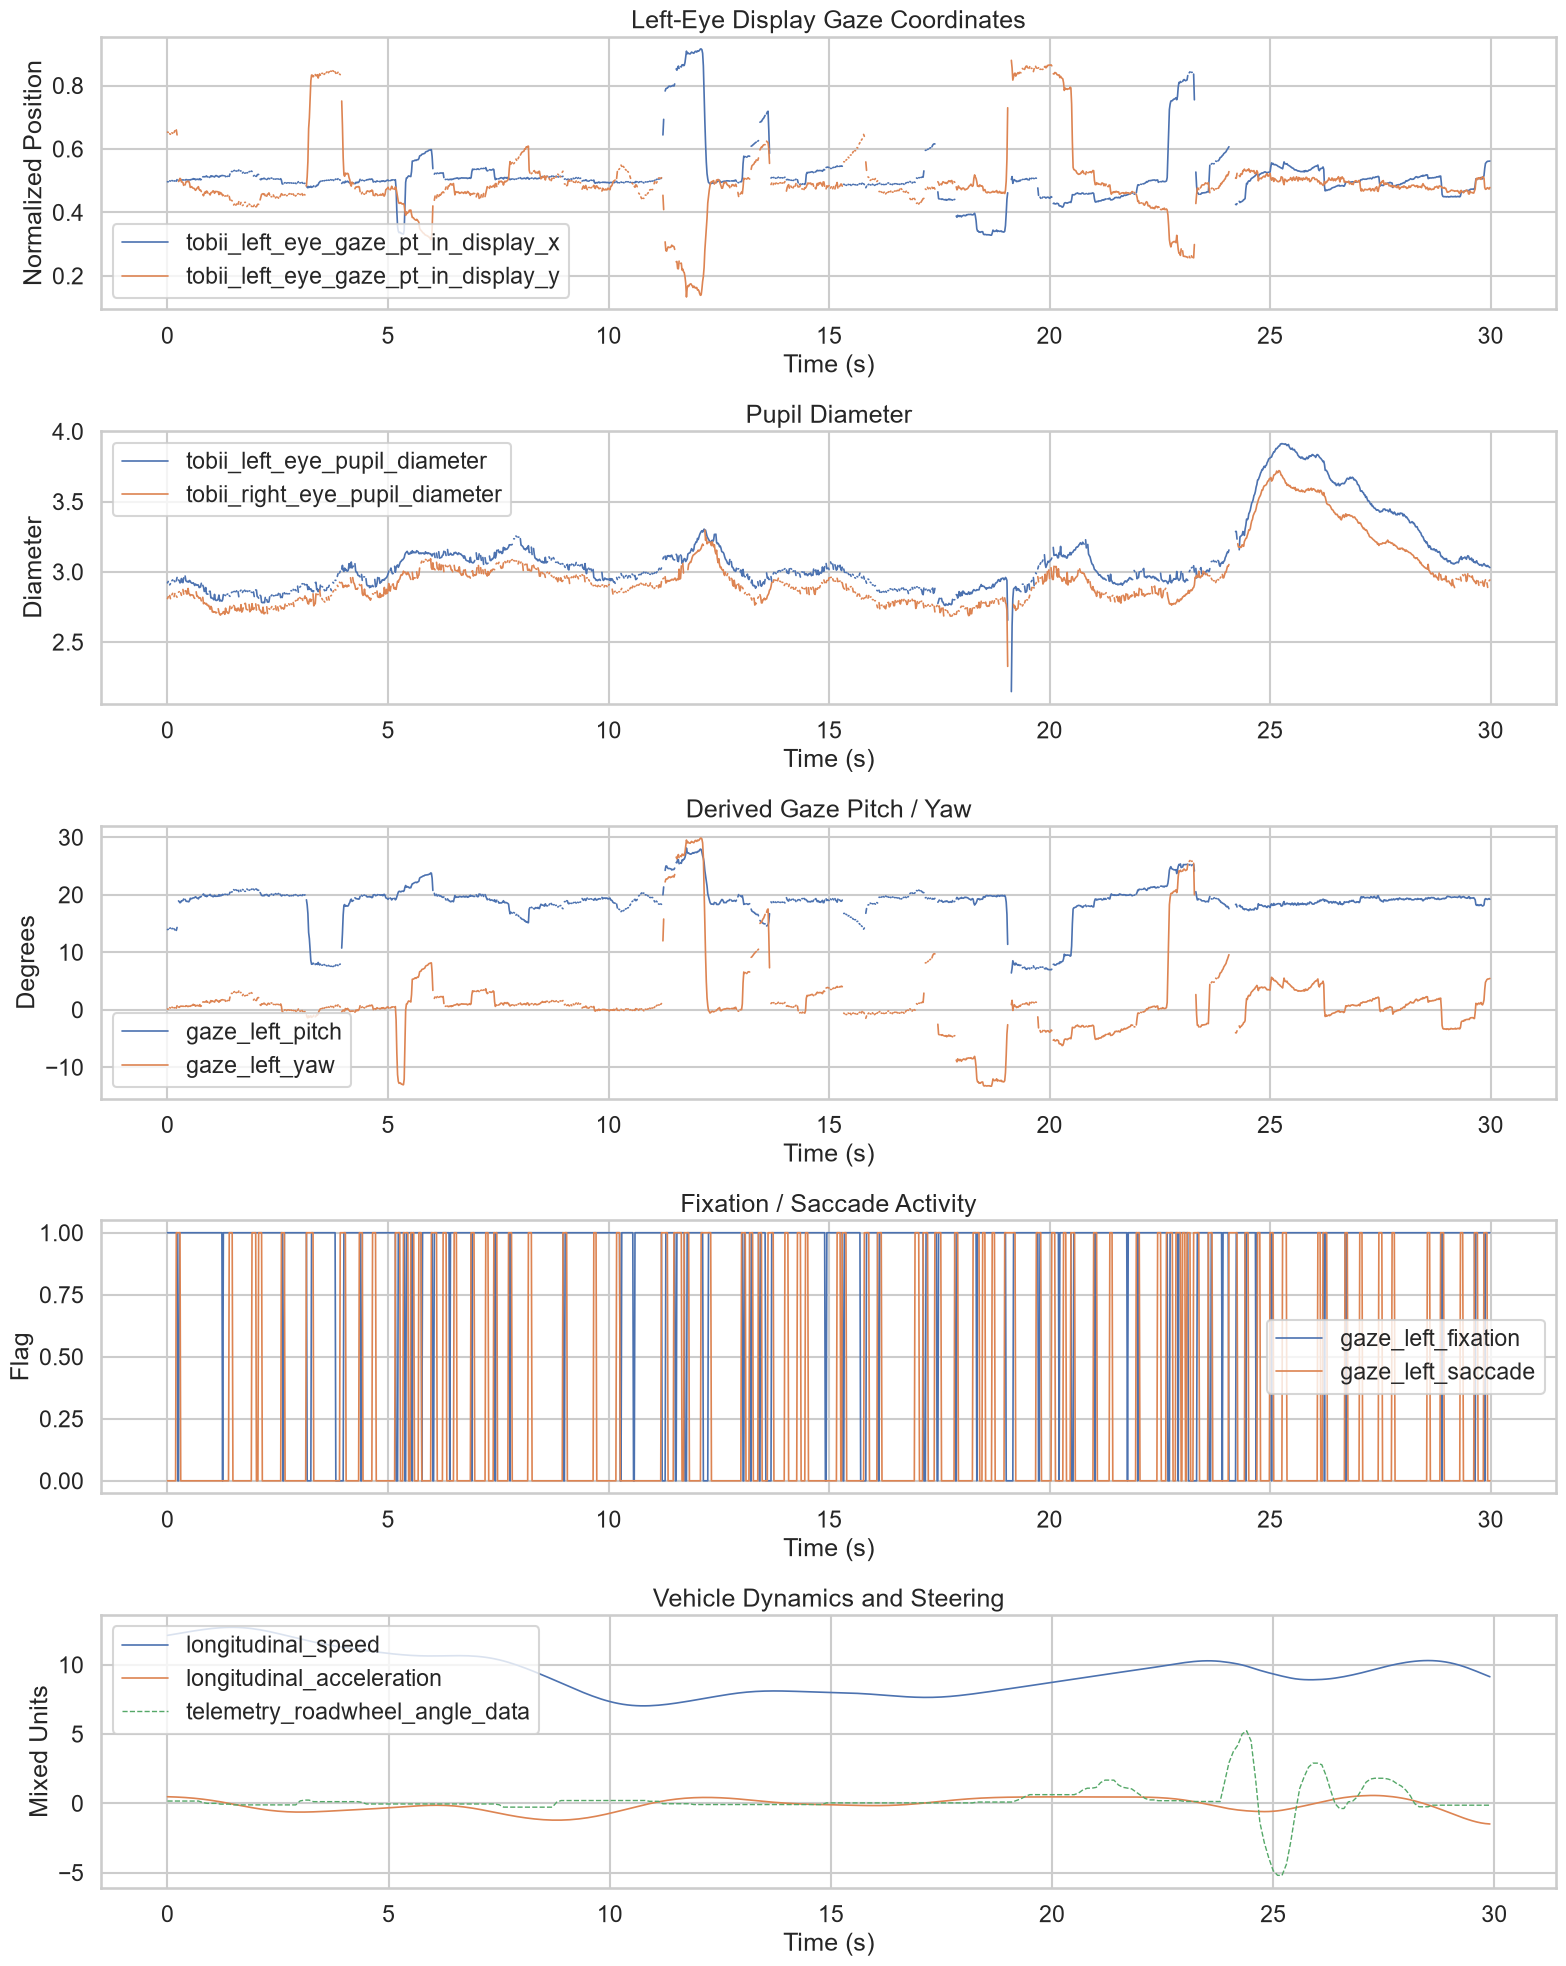

In [20]:
fig, axes = plt.subplots(5, 1, figsize=(16, 20))

tobii = sample.features.get("experiment_tobii_frame")
if tobii is not None:
    tobii_df = tobii.table.copy()
    tobii_df.index = (tobii_df.index - tobii_df.index[0]) / 1e9
    tobii_df[
        [
            "tobii_left_eye_gaze_pt_in_display_x",
            "tobii_left_eye_gaze_pt_in_display_y",
        ]
    ].plot(ax=axes[0], lw=1.2)
    tobii_df[
        [
            "tobii_left_eye_pupil_diameter",
            "tobii_right_eye_pupil_diameter",
        ]
    ].plot(ax=axes[1], lw=1.2)
    axes[0].set_title("Left-Eye Display Gaze Coordinates")
    axes[1].set_title("Pupil Diameter")
    axes[0].set_ylabel("Normalized Position")
    axes[1].set_ylabel("Diameter")
else:
    axes[0].text(0.5, 0.5, "Tobii feature missing", ha="center", va="center")
    axes[1].text(0.5, 0.5, "Tobii feature missing", ha="center", va="center")
    axes[0].set_axis_off()
    axes[1].set_axis_off()

gaze = sample.features.get("gaze_pitch_yaw")
if gaze is not None:
    gaze_df = gaze.table.copy()
    gaze_df.index = (gaze_df.index - gaze_df.index[0]) / 1e9
    gaze_df[
        [
            "gaze_left_pitch",
            "gaze_left_yaw",
        ]
    ].plot(ax=axes[2], lw=1.2)
    axes[2].set_title("Derived Gaze Pitch / Yaw")
    axes[2].set_ylabel("Degrees")
else:
    axes[2].text(0.5, 0.5, "gaze_pitch_yaw missing", ha="center", va="center")
    axes[2].set_axis_off()

fixation = sample.features.get("gaze_fixation_saccade")
if fixation is not None:
    fixation_df = fixation.table.copy()
    fixation_df.index = (fixation_df.index - fixation_df.index[0]) / 1e9
    fixation_df[
        [
            "gaze_left_fixation",
            "gaze_left_saccade",
        ]
    ].plot(ax=axes[3], lw=1.2)
    axes[3].set_title("Fixation / Saccade Activity")
    axes[3].set_ylabel("Flag")
else:
    axes[3].text(0.5, 0.5, "gaze_fixation_saccade missing", ha="center", va="center")
    axes[3].set_axis_off()

ego = sample.features.get("ego_tracks")
steering = sample.features.get("telemetry_roadwheel_angle")
if ego is not None:
    ego_df = ego.table.copy()
    ego_df.index = (ego_df.index - ego_df.index[0]) / 1e9
    ego_df[["longitudinal_speed", "longitudinal_acceleration"]].plot(ax=axes[4], lw=1.2)
if steering is not None:
    steering_df = steering.table.copy()
    steering_df.index = (steering_df.index - steering_df.index[0]) / 1e9
    steering_df[["telemetry_roadwheel_angle_data"]].plot(ax=axes[4], lw=1.0, ls="--")
axes[4].set_title("Vehicle Dynamics and Steering")
axes[4].set_ylabel("Mixed Units")

for axis in axes:
    if axis.axison:
        axis.set_xlabel("Time (s)")

fig.tight_layout()

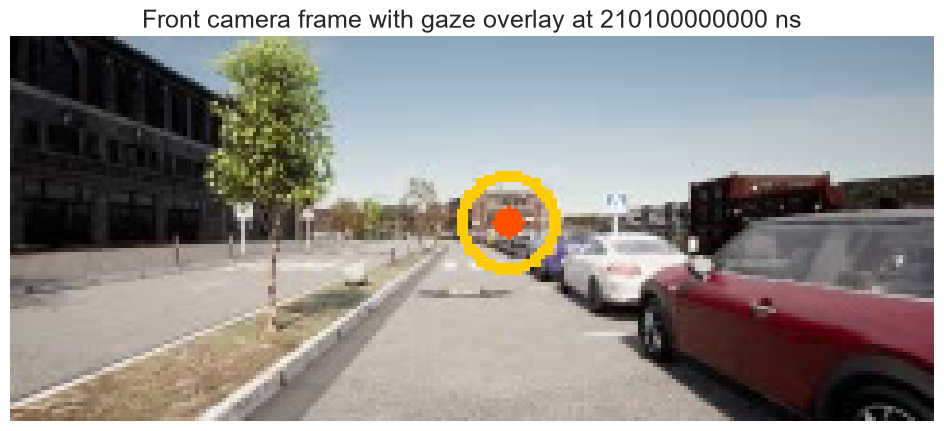

In [21]:
frame, frame_time_ns = extract_video_frame(sample, feature_name="cam_front")

if frame is None:
    print("Front video is not available in this dataset version or for this sample.")
else:
    overlay = overlay_gaze_on_frame(sample, frame, frame_time_ns)
    plt.figure(figsize=(12, 5))
    plt.imshow(overlay)
    plt.title(f"Front camera frame with gaze overlay at {frame_time_ns} ns")
    plt.axis("off")

## 4. Engineer an Aligned Multimodal Table

This is a first-pass engineering step for the PyTorch transformer:

- align all tabular modalities to a shared target timeline,
- keep raw values,
- derive explicit missing-data masks,
- derive time-since-last-observation features inspired by GRU-D,
- build a model-input table that concatenates filled values, masks, and deltas.

In [22]:
engineered = engineer_multimodal_sample(sample, target_fps=10)

engineering_summary = pd.Series(
    {
        "target_fps": 10,
        "num_frames": engineered["metadata"]["num_frames"],
        "num_value_features": engineered["values"].shape[1],
        "num_model_input_features": engineered["model_input"].shape[1],
        "impairment_label": engineered["metadata"]["impairment_label"],
    }
)

display(engineering_summary.to_frame("value"))
display(engineered["values"].head())

,value
target_fps,10
num_frames,300
num_value_features,28
num_model_input_features,84
impairment_label,baseline


,ego_tracks__carla_objects_pose_x,ego_tracks__carla_objects_pose_y,ego_tracks__lateral_acceleration,ego_tracks__lateral_jerk,ego_tracks__lateral_speed,ego_tracks__longitudinal_acceleration,ego_tracks__longitudinal_jerk,ego_tracks__longitudinal_speed,ego_tracks__yaw,experiment_tobii_frame__tobii_left_eye_gaze_pt_in_display_x,experiment_tobii_frame__tobii_left_eye_gaze_pt_in_display_y,experiment_tobii_frame__tobii_left_eye_gaze_pt_validity,experiment_tobii_frame__tobii_left_eye_pupil_diameter,experiment_tobii_frame__tobii_right_eye_gaze_pt_in_display_x,experiment_tobii_frame__tobii_right_eye_gaze_pt_in_display_y,experiment_tobii_frame__tobii_right_eye_gaze_pt_validity,experiment_tobii_frame__tobii_right_eye_pupil_diameter,gaze_fixation_saccade__gaze_left_fixation,gaze_fixation_saccade__gaze_left_fixation_saccade_ratio,gaze_fixation_saccade__gaze_left_saccade,gaze_fixation_saccade__gaze_right_fixation,gaze_fixation_saccade__gaze_right_fixation_saccade_ratio,gaze_fixation_saccade__gaze_right_saccade,gaze_pitch_yaw__gaze_left_pitch,gaze_pitch_yaw__gaze_left_yaw,gaze_pitch_yaw__gaze_right_pitch,gaze_pitch_yaw__gaze_right_yaw,telemetry_roadwheel_angle__telemetry_roadwheel_angle_data
resampled_epoch_ns,,,,,,,,,,,,,,,,,,,,,,,,,,,,
195100000000,143.226730,-333.332336,-0.094964,-0.003923,-0.009361,0.477397,-0.064731,12.125929,49.690140,0.496613,0.653269,True,2.921753,0.499441,0.632951,True,2.809723,1,12.521739,0,1,11.600000,0,13.955597,0.124610,14.701241,-5.394879,0.166946
195200000000,142.300705,-332.548340,-0.093622,0.014272,-0.008676,0.467831,-0.090559,12.180253,49.761398,0.500415,0.651028,True,2.937378,0.498386,0.646307,True,2.837311,1,12.521739,0,1,11.600000,0,14.086667,0.448775,14.317788,-5.476149,0.166854
195300000000,141.369385,-331.761871,-0.090687,0.032520,-0.007565,0.455336,-0.121033,12.234736,49.833450,0.498440,0.660076,True,2.936172,0.497840,0.650757,True,2.827667,1,12.521739,1,1,11.600000,1,13.808051,0.286857,14.188050,-5.515334,0.166763
195400000000,140.432999,-330.973114,-0.086203,0.050319,-0.005871,0.439514,-0.156191,12.289076,49.905655,0.502535,0.504721,True,2.927567,0.488803,0.496104,True,2.851028,1,9.862069,0,1,9.290323,1,18.693084,0.625358,19.053688,-6.264907,0.166671
195500000000,139.491867,-330.182373,-0.080247,0.067165,-0.003345,0.419992,-0.195881,12.342881,49.977829,0.501959,0.486892,True,2.970337,0.488823,0.488036,True,2.863678,1,9.862069,0,1,9.000000,0,19.199160,0.576535,19.257614,-6.265492,0.166578


,missing_rate
gaze_pitch_yaw__gaze_right_yaw,0.083333
experiment_tobii_frame__tobii_right_eye_pupil_diameter,0.083333
experiment_tobii_frame__tobii_right_eye_gaze_pt_in_display_y,0.083333
experiment_tobii_frame__tobii_right_eye_gaze_pt_in_display_x,0.083333
gaze_pitch_yaw__gaze_right_pitch,0.083333
experiment_tobii_frame__tobii_left_eye_pupil_diameter,0.043333
gaze_pitch_yaw__gaze_left_pitch,0.043333
gaze_pitch_yaw__gaze_left_yaw,0.043333
experiment_tobii_frame__tobii_left_eye_gaze_pt_in_display_x,0.043333
experiment_tobii_frame__tobii_left_eye_gaze_pt_in_display_y,0.043333


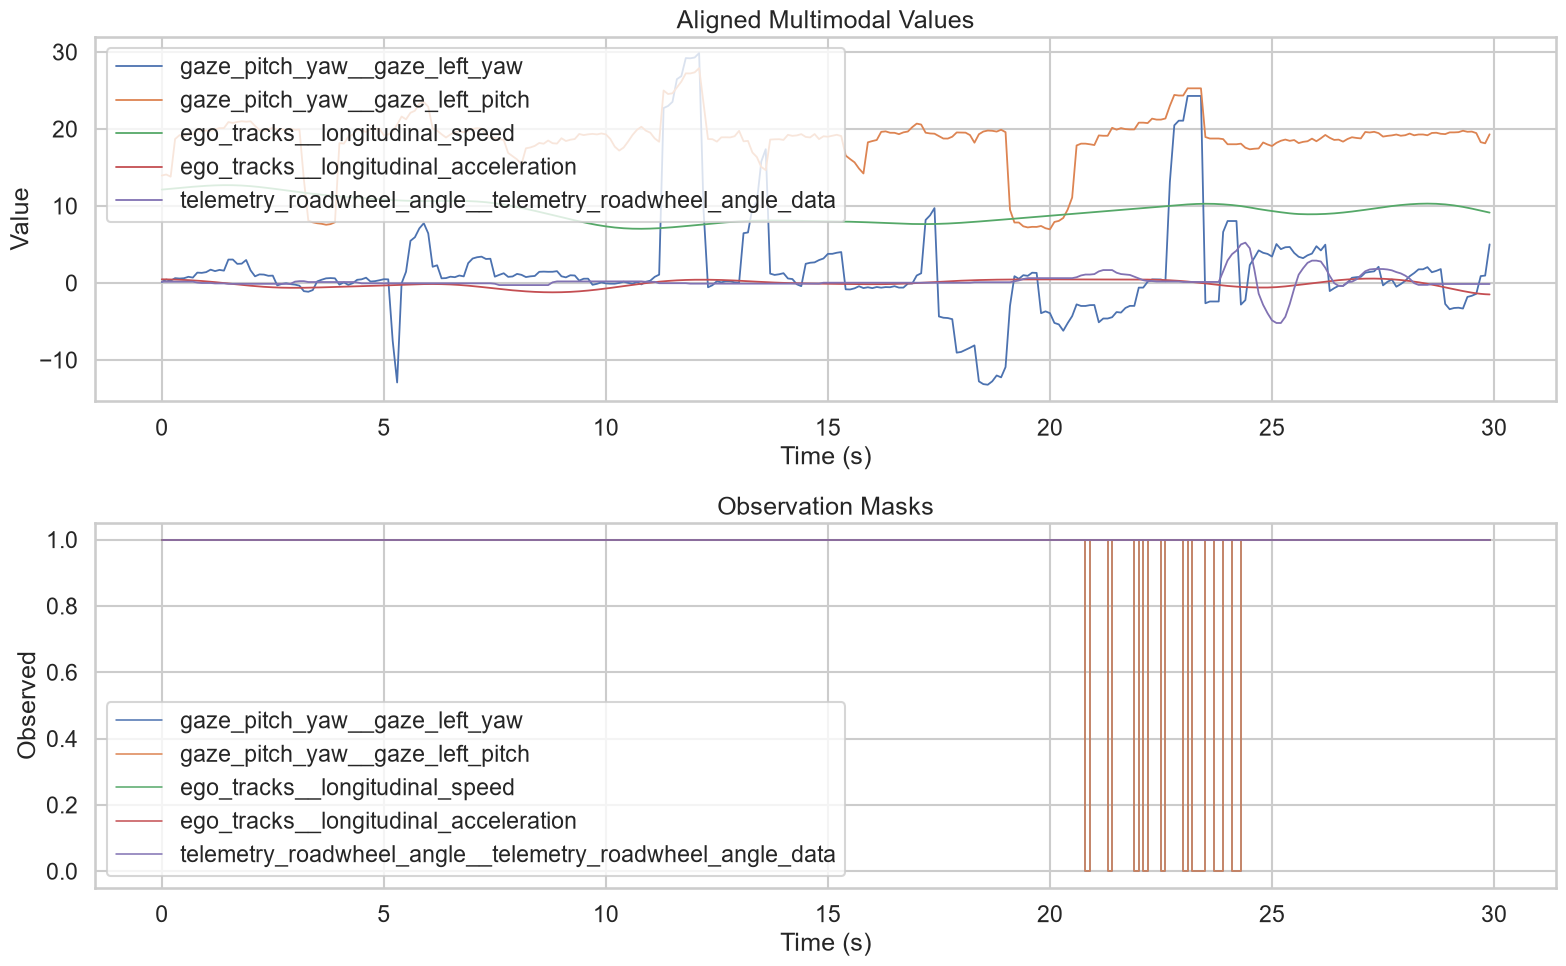

In [23]:
missing_rate = (1.0 - engineered["masks"].mean()).sort_values(ascending=False)
display(missing_rate.head(20).to_frame("missing_rate"))

selected_value_cols = [
    column
    for column in [
        "gaze_pitch_yaw__gaze_left_yaw",
        "gaze_pitch_yaw__gaze_left_pitch",
        "ego_tracks__longitudinal_speed",
        "ego_tracks__longitudinal_acceleration",
        "telemetry_roadwheel_angle__telemetry_roadwheel_angle_data",
    ]
    if column in engineered["filled_values"].columns
]
selected_mask_cols = [column for column in selected_value_cols if column in engineered["masks"].columns]

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

plot_values = engineered["filled_values"][selected_value_cols].copy()
plot_values.index = engineered["timeline_s"]
plot_values.plot(ax=axes[0], lw=1.3)
axes[0].set_title("Aligned Multimodal Values")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Value")

plot_masks = engineered["masks"][selected_mask_cols].copy()
plot_masks.index = engineered["timeline_s"]
plot_masks.plot(ax=axes[1], lw=1.1, drawstyle="steps-post")
axes[1].set_title("Observation Masks")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Observed")

fig.tight_layout()

In [24]:
sample_tag = "_".join(
    [
        sample.participant.name,
        sample.scenario.scenario_name.replace("/", "__").replace("-", "_"),
        "10hz",
    ]
)

model_input_path = artifact_dir / f"{sample_tag}_model_input.pkl"
metadata_path = artifact_dir / f"{sample_tag}_metadata.csv"

engineered["model_input"].to_pickle(model_input_path)
pd.Series(engineered["metadata"]).to_csv(metadata_path, header=["value"])

print(f"Saved engineered model input to {model_input_path}")
print(f"Saved sample metadata to {metadata_path}")

Saved engineered model input to C:\projects\DriverStateNet\artifacts\bootstrap\7224_driving__2b_vehicle_door_open_hazard_10hz_model_input.pkl
Saved sample metadata to C:\projects\DriverStateNet\artifacts\bootstrap\7224_driving__2b_vehicle_door_open_hazard_10hz_metadata.csv
